#EX-4

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_excel('Student_placements.xlsx')
df.head()

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No


In [6]:
new_df=df.drop(columns='College_ID')
new_df.head() 
 

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,107,6.61,6.28,8,No,8,8,4,No
1,97,5.52,5.37,8,No,7,8,0,No
2,109,5.36,5.83,9,No,3,1,1,No
3,122,5.47,5.75,6,Yes,1,6,1,No
4,96,7.91,7.69,7,No,8,10,2,No


In [43]:
# Label encoding for categorical columns
from sklearn import preprocessing
LE=preprocessing.LabelEncoder()
new_df['Internship_Experience'] = LE.fit_transform(new_df['Internship_Experience'])
new_df['Placement']=LE.fit_transform(new_df['Placement'])
new_df.head()

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,107,6.61,6.28,8,0,8,8,4,0
1,97,5.52,5.37,8,0,7,8,0,0
2,109,5.36,5.83,9,0,3,1,1,0
3,122,5.47,5.75,6,0,1,6,1,0
4,96,7.91,7.69,7,0,8,10,2,0


In [44]:
#scaling all columns
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [45]:
cols = new_df.columns
new_df_scaled=scaler.fit_transform(new_df)
new_df_scaled = pd.DataFrame(new_df_scaled, columns = cols)
new_df_scaled.head()

,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,0.500135,-0.639521,-0.851919,0.853921,0.0,0.958593,0.840550,0.866381,-0.445979
1,-0.164214,-1.392572,-1.470939,0.853921,0.0,0.642131,0.840550,-1.464794,-0.445979
2,0.633004,-1.503111,-1.158028,1.201949,0.0,-0.623713,-1.572644,-0.882000,-0.445979
3,1.496657,-1.427115,-1.212447,0.157865,0.0,-1.256636,0.151066,-0.882000,-0.445979
4,-0.230648,0.258612,0.107220,0.505893,0.0,0.958593,1.530034,-0.299206,-0.445979


In [46]:
x=new_df.drop(columns='Placement')
y=new_df['Placement']


In [47]:
from sklearn.decomposition import PCA


In [48]:
pca =PCA()
pca.fit(x)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [49]:
print('Components: \n', pca.components_)
print('Explained variance ratio: \n',
pca. explained_variance_ratio_)

Components: 
 [[ 9.99994938e-01 -2.57815384e-04 -2.83273629e-04 -1.35174398e-03
   0.00000000e+00 -7.60153098e-04 -2.17983508e-03  1.67933662e-03]
 [ 8.65387688e-04  7.35624053e-03  8.52538377e-03  5.95206139e-02
  -2.77555756e-17  9.98040454e-01  1.45384068e-02  5.79976951e-03]
 [ 1.14564484e-03 -1.17383753e-02 -1.30517987e-02 -5.25873040e-01
  -0.00000000e+00  1.91587044e-02  8.50160953e-01  2.71886848e-03]
 [ 2.26308815e-03 -1.52086468e-02 -1.45587397e-02  8.48347038e-01
  -5.55111512e-17 -5.79380317e-02  5.25663095e-01 -1.34319355e-02]
 [ 3.51179266e-04  7.00148920e-01  7.11354996e-01  8.62520691e-03
   1.11022302e-16 -1.24416529e-02  2.60320521e-02  5.34656810e-02]
 [-1.67840699e-03 -3.87743176e-02 -3.72503366e-02  1.20377080e-02
   1.38777878e-17 -5.96245159e-03  3.28227161e-03  9.98456267e-01]
 [-1.63366779e-05  7.12646314e-01 -7.01520786e-01  1.00883638e-03
  -1.21569421e-14  6.75694550e-04 -3.26140312e-04  1.49572587e-03]
 [-1.93607837e-19  8.58922296e-15 -8.56474627e-15  6.98

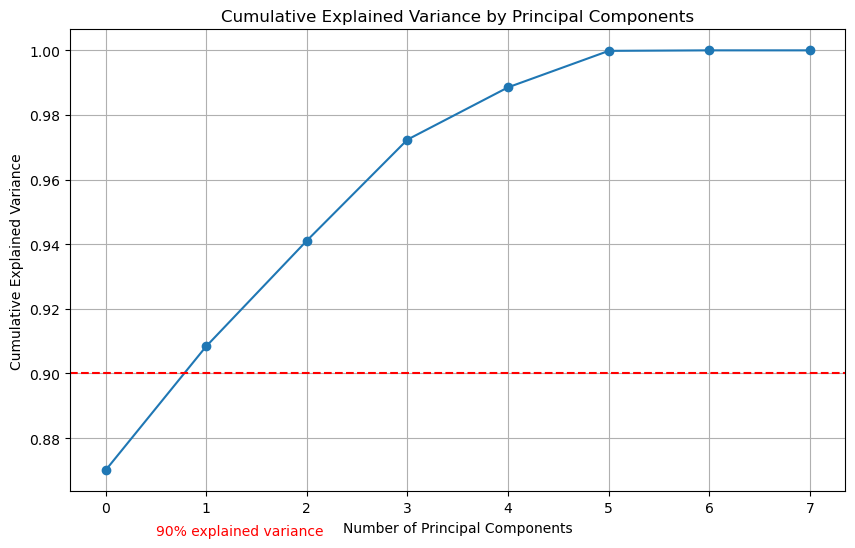

In [50]:
# calculating cumulative explained variance by the features
cumulative_variance = np. cumsum(pca. explained_variance_ratio_)
plt.figure(figsize=(10,6))
plt.plot(cumulative_variance, marker ='o')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance by Principal Components')
plt.grid(True)
plt.axhline(y=0.9, linestyle = '--', color = 'red')
plt.text(0.5, 0.85, '90% explained variance', color = 'red')
plt.show()

#CONCLUSION